In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from sklearn.datasets import make_classification


In [3]:
X, y = make_classification(n_samples=100, n_features=2, n_informative=1, n_redundant=0,
                           n_classes=2, n_clusters_per_class=1, random_state=41, hypercube=False, class_sep=10)

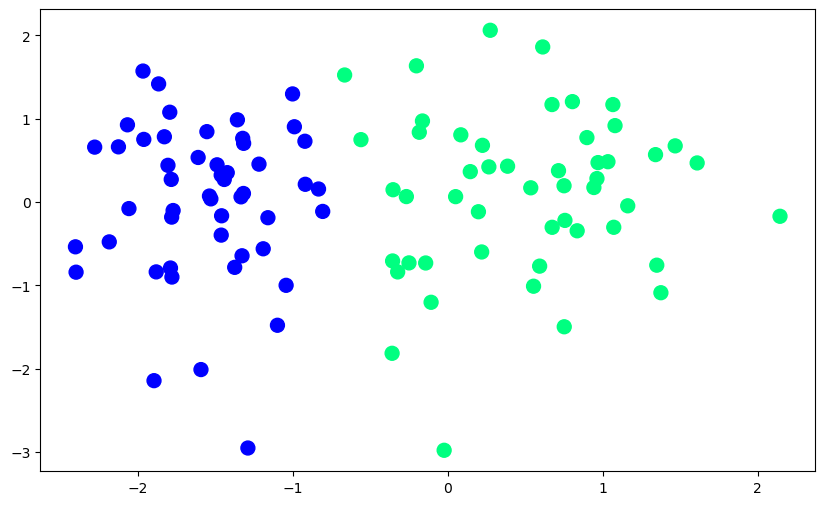

In [4]:
plt.figure(figsize=(10,6))
plt.scatter(X[:,0],X[:,1],c=y,cmap="winter",s=100)
plt.show()

In [5]:
def perceptron(X,y):
    X = np.insert(X,0,1,axis=1)
    weights = np.ones(X.shape[1])
    lr = 0.1

    for i in range(1000):
        j = np.random.randint(0,100)
        y_hat = step(np.dot(X[j],weights))
        weights = weights + lr*(y[j]-y_hat)*X[j]

    return weights[0],weights[1:]


In [6]:
def step(z):
    return 1 if z>0 else 0

In [7]:
intercept_,coef_ = perceptron(X,y)

In [9]:
print(coef_)
print(intercept_)

[1.3346635  0.14854573]
1.0


In [10]:
m = -(coef_[0]/coef_[1])
b = -(intercept_/coef_[1])

In [11]:
x_input = np.linspace(-3,3,100)
y_input = m*x_input + b

(-3.0, 2.0)

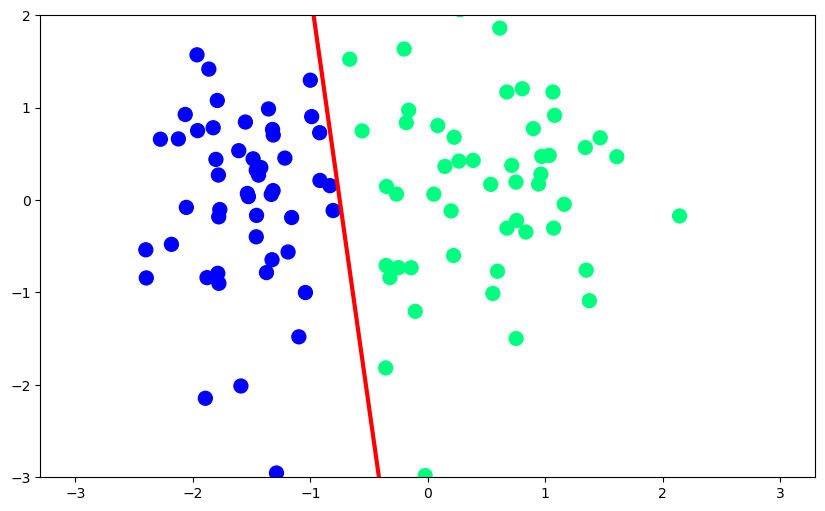

In [12]:
plt.figure(figsize=(10,6))
plt.plot(x_input,y_input,color='red',linewidth=3)
plt.scatter(X[:,0],X[:,1],c=y,cmap='winter',s=100)
plt.ylim(-3,2)

In [23]:

%matplotlib inline

from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots(figsize=(9, 5))

x_i = np.arange(-3, 3, 0.1)

ax.scatter(X[:, 0], X[:, 1], c=y, cmap='winter', s=100)

line, = ax.plot(x_i, x_i*m[0] + b[0], 'r-', linewidth=2)

ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)

def update(i):
    line.set_ydata(x_i*m[i] + b[i])
    ax.set_xlabel('Epoch {}'.format(i+1))
    return line,

anim = FuncAnimation(
    fig,
    update,
    frames=len(m),
    interval=100,
    repeat=True
)

plt.close(fig)

HTML(anim.to_jshtml())
